In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os
from google.colab import drive
import zipfile

# 1. Hubungkan ke Google Drive
drive.mount('/content/drive')

# 2. Ekstrak dataset (Perhatikan nama file-nya ya)
if not os.path.exists('/content/dataset_xray'):
    print("Sedang mengekstrak dataset...")
    # Kita ubah namanya jadi 'archive (1).zip'
    with zipfile.ZipFile('/content/drive/MyDrive/archive (1).zip', 'r') as zip_ref:
        zip_ref.extractall('/content/dataset_xray')
    print("Ekstrak selesai!")
else:
    print("Dataset sudah ada, lanjut ke tahap berikutnya.")

# 3. Tentukan lokasi folder
base_dir = '/content/dataset_xray/chest_xray'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# 4. Parameter Dasar
batch_size = 32
img_height = 150
img_width = 150

Mounted at /content/drive
Sedang mengekstrak dataset...
Ekstrak selesai!


In [2]:
# Load Data Latih (80% dari folder train)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2, # Potong 20% buat validasi
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    color_mode="grayscale"
)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.


In [3]:
# Load Data Validasi (20% sisa dari folder train)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    color_mode="grayscale"
)

Found 5216 files belonging to 2 classes.
Using 1043 files for validation.


In [4]:
# Load Data Uji (Tetap pakai folder test yang asli)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    color_mode="grayscale",
    shuffle=False
)

Found 624 files belonging to 2 classes.


In [5]:
model = models.Sequential([
    # NORMALISASI: Ubah piksel 0-255 jadi 0-1 biar AI lebih stabil
    layers.Rescaling(1./255, input_shape=(img_height, img_width, 1)),

    # AUGMENTASI: AI belajar dari gambar yang diputar/dibalik
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),

    # --- BLOK 1 ---
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # --- BLOK 2 ---
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # --- BLOK 3 ---
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # --- KLASIFIKASI ---
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [6]:
import tensorflow as tf

# Mengatur rem otomatis agar AI berhenti kalau tidak ada kemajuan
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
print("EarlyStopping berhasil diatur.")

EarlyStopping berhasil diatur.


In [7]:
# Memberitahu AI cara mengukur kesalahan dan cara memperbaiki diri
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
print("Model berhasil di-compile dan siap dilatih.")

Model berhasil di-compile dan siap dilatih.


In [8]:
print("Memulai proses training...")

epochs = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[early_stop]
)

print("Training selesai!")

Memulai proses training...
Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 33s 189ms/step - accuracy: 0.7819 - loss: 0.4798 - val_accuracy: 0.8619 - val_loss: 0.2896
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 23s 176ms/step - accuracy: 0.8713 - loss: 0.3028 - val_accuracy: 0.9243 - val_loss: 0.1845
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 25s 190ms/step - accuracy: 0.8946 - loss: 0.2493 - val_accuracy: 0.9243 - val_loss: 0.1633
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 23s 175ms/step - accuracy: 0.9238 - loss: 0.1981 - val_accuracy: 0.9482 - val_loss: 0.1403
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 42s 181ms/step - accuracy: 0.9322 - loss: 0.1791 - val_accuracy: 0.9444 - val_loss: 0.1320
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 182ms/step - accuracy: 0.9370 - loss: 0.1607 - val_accuracy: 0.9434 - val_loss: 0.1431
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 180ms/step - accuracy: 0.9456 - loss: 0.1530 - val_accuracy: 0.9329 - val_loss: 0.1614
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 181ms/step -

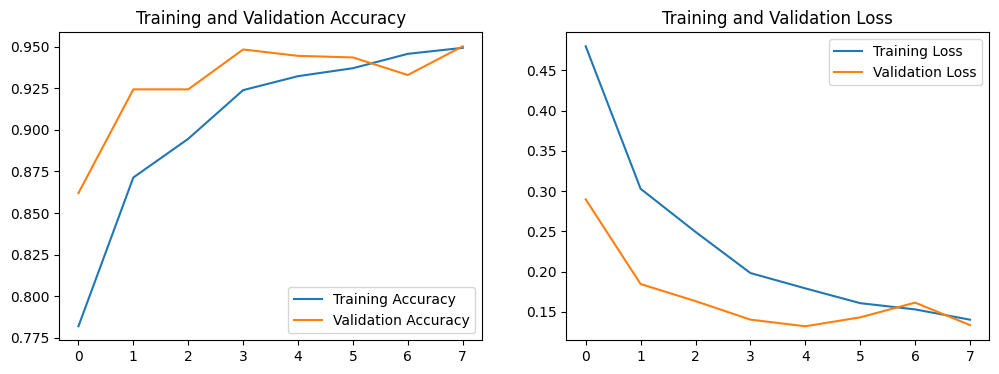

In [9]:
import matplotlib.pyplot as plt

# Ambil data riwayat training
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# Grafik Loss (Error)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

In [10]:
import numpy as np
from sklearn.metrics import classification_report

# 1. Ambil kunci jawaban asli dari data uji
y_true = np.concatenate([y for x, y in test_ds], axis=0)

# 2. AI nembak jawabannya
y_pred_probs = model.predict(test_ds)

# 3. Ubah probabilitas jadi angka 0 atau 1 (threshold 0.5)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

# 4. Tampilkan hasil
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=['Pneumonia', 'Normal']))

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step
=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   Pneumonia       0.92      0.67      0.77       234
      Normal       0.83      0.97      0.89       390

    accuracy                           0.85       624
   macro avg       0.88      0.82      0.83       624
weighted avg       0.86      0.85      0.85       624



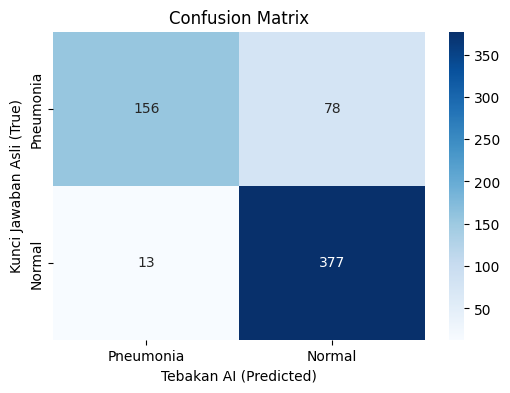


Model berhasil disimpan dengan nama 'model_pneumonia_from_scratch.h5'!


In [11]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Bikin Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# 2. Gambar visualnya
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pneumonia', 'Normal'],
            yticklabels=['Pneumonia', 'Normal'])
plt.ylabel('Kunci Jawaban Asli (True)')
plt.xlabel('Tebakan AI (Predicted)')
plt.title('Confusion Matrix')
plt.show()

# 3. Simpan model ke laptop/Drive
model.save('model_pneumonia_from_scratch.h5')
print("\nModel berhasil disimpan dengan nama 'model_pneumonia_from_scratch.h5'!")

Silakan upload gambar X-Ray:


Saving normal.jpeg to normal.jpeg

Memproses gambar: normal.jpeg


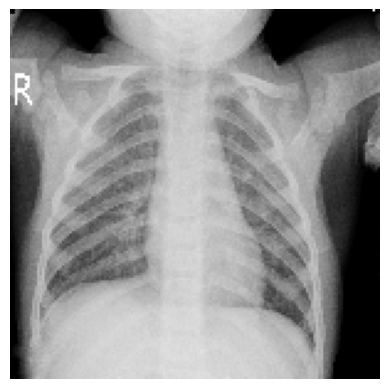

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Nilai Probabilitas: 0.4195
HASIL: 🟢 NORMAL
Tingkat Keyakinan: 58.05%


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow.keras.preprocessing import image

print("Silakan upload gambar X-Ray:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\nMemproses gambar: {filename}")

    # Preprocessing
    img = image.load_img(filename, target_size=(150, 150), color_mode="grayscale")
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Prediksi
    prediction = model.predict(img_array)
    prob = prediction[0][0]

    print(f"Nilai Probabilitas: {prob:.4f}")

    # LOGIKA YANG BENAR (Sudah dibalik)
    if prob > 0.5:
        print("HASIL: 🔴 PNEUMONIA") # Probabilitas > 0.5 artinya Kelas 1 (Pneumonia)
        print(f"Tingkat Keyakinan: {prob * 100:.2f}%")
    else:
        print("HASIL: 🟢 NORMAL")    # Probabilitas < 0.5 artinya Kelas 0 (Normal)
        print(f"Tingkat Keyakinan: {(1 - prob) * 100:.2f}%")